# Planetary Defense Analytics — 04: Case 3 Clustering

**Goal:** group asteroids by orbital elements, **independent of the PHA/NEO labels**, and check whether the groups match known orbital families.

**Features (as in the reference benchmark):** `a`, `e`, `i`, `per`, `moid_ld`  
**Methods:** K-Means (k chosen by elbow + silhouette) and DBSCAN (eps chosen from a k-distance graph).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import os, warnings
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("../models", exist_ok=True)

## 2. Load data and build clustering features

In [2]:
df = pd.read_parquet("../data/cleaned.parquet")
clu = df.dropna(subset=['a', 'e', 'i', 'per', 'moid_ld']).copy()

def cluster_features(d):
    return pd.DataFrame({
        'log_a': np.log10(d['a']),
        'e': d['e'],
        'i': d['i'],
        'log_per': np.log10(d['per']),
        'log_moid_ld': np.log10(d['moid_ld'] + 1e-3),
    }, index=d.index)

X = cluster_features(clu)
print("Rows:", X.shape)
X.describe().T

Rows: (932337, 5)


,count,mean,std,min,25%,50%,75%,max
log_a,932337.0,0.427217,0.107780,-0.255380,0.378232,0.422913,0.477553,4.524901
e,932337.0,0.156221,0.093001,0.000000,0.092159,0.144933,0.200589,0.999851
i,932337.0,8.996685,6.606943,0.007744,4.135558,7.357845,12.332703,175.082901
log_per,932337.0,3.203424,0.161670,2.179528,3.129947,3.196968,3.278928,9.349950
log_moid_ld,932337.0,2.656923,0.306226,-2.929281,2.581459,2.684014,2.792547,4.490379


**Preprocessing choices**
- `a`, `per` and `moid_ld` are heavily right-skewed (span several orders of magnitude) → log10, otherwise the few distant objects would dominate the distances.
- All features are standardised — K-Means and DBSCAN are distance-based, so unscaled inclination (degrees) would outweigh eccentricity (0–1).
- Labels (`pha`, `neo`, `class`) are **not** used for clustering — only for interpreting clusters afterwards.
- Note: `a` and `per` are linked by Kepler's third law (per ∝ a^1.5), so they carry the same information; they are kept to match the benchmark feature set, which effectively gives orbit size double weight.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# samples for the expensive steps
rng = np.random.RandomState(RANDOM_STATE)
idx_200k = rng.choice(len(X_scaled), size=min(200000, len(X_scaled)), replace=False)
idx_20k  = rng.choice(len(X_scaled), size=min(20000,  len(X_scaled)), replace=False)

## 3. K-Means — choosing k
- **Elbow:** inertia (within-cluster spread) for k = 2…10 on a 200k sample.
- **Silhouette:** how well-separated clusters are (−1 to 1, higher is better), on a 20k sample.

k=2  inertia=775,194  silhouette=0.871
k=3  inertia=570,399  silhouette=0.721
k=4  inertia=443,327  silhouette=0.293
k=5  inertia=355,809  silhouette=0.308
k=6  inertia=316,342  silhouette=0.315
k=7  inertia=284,341  silhouette=0.300
k=8  inertia=261,820  silhouette=0.295
k=9  inertia=241,091  silhouette=0.299
k=10  inertia=222,803  silhouette=0.296


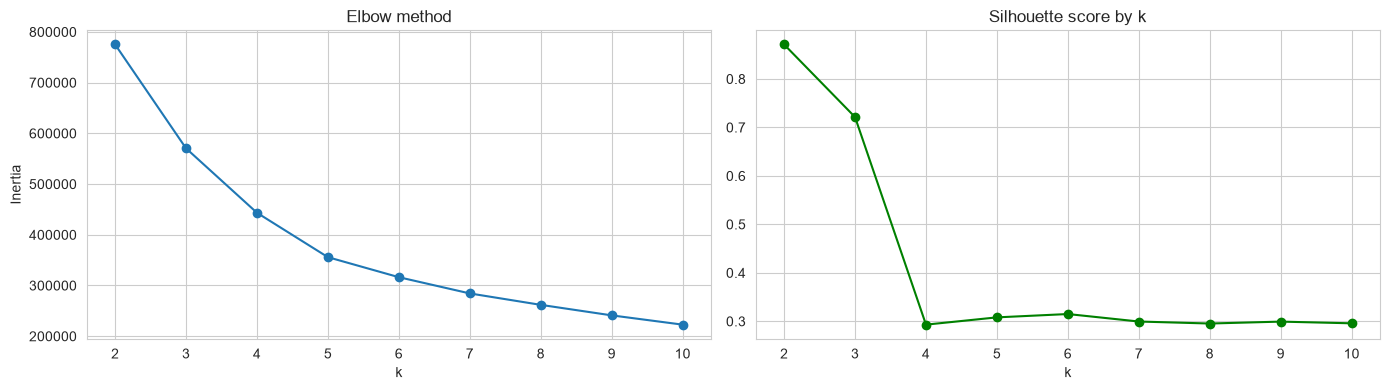

In [4]:
k_range = range(2, 11)
inertias, sils = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(X_scaled[idx_200k])
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled[idx_20k], km.predict(X_scaled[idx_20k])))
    print(f"k={k}  inertia={km.inertia_:,.0f}  silhouette={sils[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(k_range), inertias, 'o-'); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), sils, 'o-', color='green'); axes[1].set_title("Silhouette score by k"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

In [5]:
best_k = list(k_range)[int(np.argmax(sils))]
print("k with highest silhouette:", best_k)
# Override manually if the elbow suggests a different, more interpretable k:
best_k = 5

k with highest silhouette: 2


**Justification:** k = 2 and k = 3 have the highest silhouette (0.87, 0.72), but only because a few distant objects (TNOs) are separated from everything else, so the main asteroid population is not split. The elbow is at **k = 5**: inertia drops sharply up to k = 5, then flattens. k = 5 gives silhouette 0.308 (benchmark ≈ 0.35) and astronomically meaningful clusters.

## 4. Final K-Means model

In [6]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
clu['cluster'] = kmeans.labels_
km_sil = silhouette_score(X_scaled[idx_20k], kmeans.labels_[idx_20k])
print(f"K-Means k={best_k}  silhouette = {km_sil:.3f}   (benchmark ≈ 0.35)")
clu['cluster'].value_counts().sort_index()

K-Means k=5  silhouette = 0.308   (benchmark ≈ 0.35)


cluster
0    327878
1    372713
2      3766
3     20867
4    207113
Name: count, dtype: int64

## 5. Interpreting the clusters

### 5.1 Cluster profiles (median orbital elements)

In [7]:
profile = clu.groupby('cluster').agg(
    count=('a', 'size'), a_AU=('a', 'median'), e=('e', 'median'), i_deg=('i', 'median'),
    per_years=('per_y', 'median'), moid_ld=('moid_ld', 'median'),
    pct_neo=('neo', lambda s: s.mean() * 100), pct_pha=('pha', lambda s: s.mean() * 100))
profile.round(3)

,count,a_AU,e,i_deg,per_years,moid_ld,pct_neo,pct_pha
cluster,,,,,,,,
0,327878,3.003,0.088,8.343,5.204,648.490,0.000,0.000
1,372713,2.394,0.171,4.794,3.704,395.661,0.197,0.000
2,3766,43.768,0.163,10.642,289.561,14006.306,0.106,0.000
3,20867,1.674,0.465,8.388,2.165,17.096,100.000,9.901
4,207113,2.665,0.187,15.621,4.351,469.467,0.618,0.000


### 5.2 Clusters vs expert orbital class

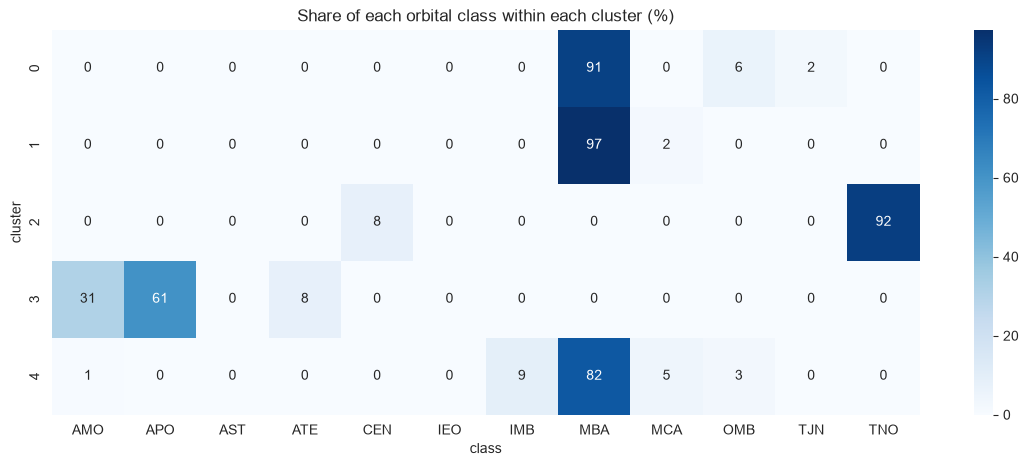

In [8]:
ct = pd.crosstab(clu['cluster'], clu['class'], normalize='index') * 100
plt.figure(figsize=(14, 5))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues")
plt.title("Share of each orbital class within each cluster (%)"); plt.show()

In [9]:
dominant = ct.idxmax(axis=1)
share = ct.max(axis=1)
cluster_names = {c: f"Cluster {c} — mostly {dominant[c]} ({share[c]:.0f}%)" for c in ct.index}
for v in cluster_names.values():
    print(v)

Cluster 0 — mostly MBA (91%)
Cluster 1 — mostly MBA (97%)
Cluster 2 — mostly TNO (92%)
Cluster 3 — mostly APO (61%)
Cluster 4 — mostly MBA (82%)


**Cluster interpretation (k = 5):**

| Cluster | Size | Dominant class | Meaning |
|---|---|---|---|
| 0 | 327,878 | MBA (91%) | Main belt, sub-group 1 |
| 1 | 372,713 | MBA (97%) | Main belt, sub-group 2 (the "purest" main-belt group) |
| 4 | 207,113 | MBA (82%) | Main belt, sub-group 3, mixed with neighbouring classes |
| 3 | 20,867 | APO (61%) | **Near-Earth objects**: the cluster where PHAs concentrate |
| 2 | 3,766 | TNO (92%) | **Trans-Neptunian objects**: the far outer Solar System |

- **Without using any labels**, K-Means rediscovered the main known populations: the main belt, near-Earth objects and the distant TNOs.
- The main belt (~89% of all asteroids) is split into **3 sub-groups**, likely by distance from the Sun and inclination, similar to the inner/middle/outer belt division used by astronomers.
- **Cluster 3** is the most important for planetary defense: it is dominated by Apollo asteroids and holds most of the hazardous objects (see `pct_pha` in the Section 5.1 profile table).
- The silhouette of 0.308 reflects that the main belt is one continuous population, so its sub-groups overlap at their edges; the near-Earth and TNO clusters are clearly separated.

### 5.3 Visualising clusters (semi-major axis vs eccentricity)

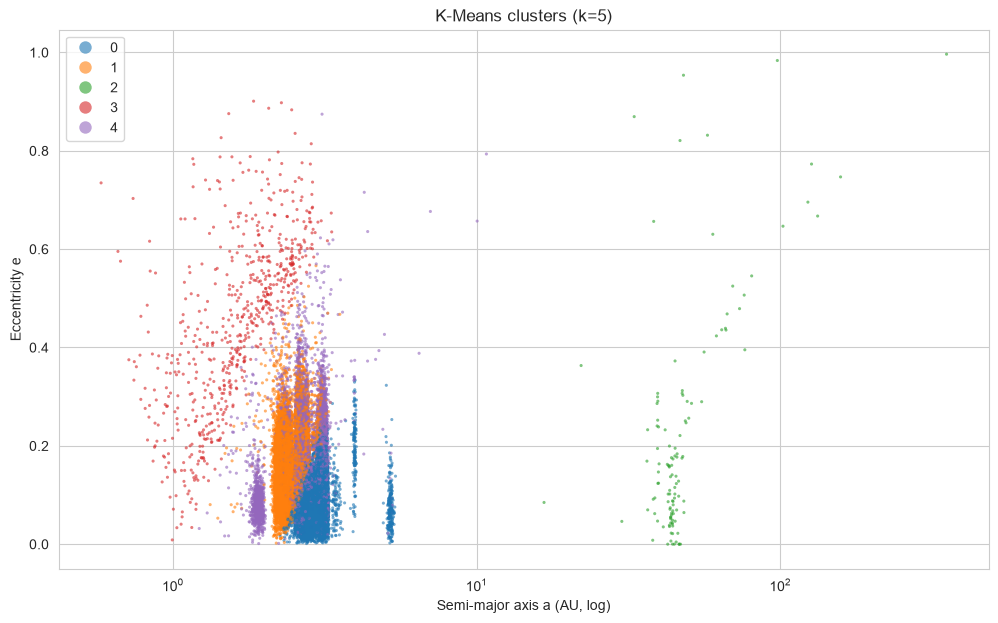

In [10]:
plot_df = clu.sample(30000, random_state=RANDOM_STATE)
plt.figure(figsize=(12, 7))
sns.scatterplot(data=plot_df, x='a', y='e', hue='cluster', palette='tab10', s=5, alpha=0.6, linewidth=0)
plt.xscale('log'); plt.xlabel("Semi-major axis a (AU, log)"); plt.ylabel("Eccentricity e")
plt.title(f"K-Means clusters (k={best_k})"); plt.legend(markerscale=4); plt.show()

## 6. DBSCAN — tuning eps and min_samples
DBSCAN needs pairwise neighbour searches, so it runs on a 30k sample.

**k-distance graph:** for each point, distance to its k-th nearest neighbour (k = min_samples), sorted. The "knee" — where the curve bends sharply upward — is a good eps.

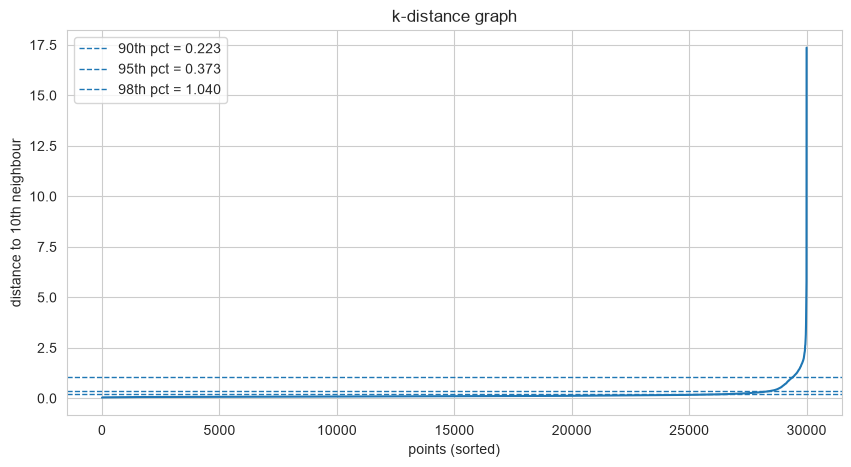

In [11]:
idx_30k = rng.choice(len(X_scaled), size=min(30000, len(X_scaled)), replace=False)
X_db = X_scaled[idx_30k]

MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_db)
dists = np.sort(nn.kneighbors(X_db)[0][:, -1])

plt.figure(figsize=(10, 5))
plt.plot(dists)
for q in [0.90, 0.95, 0.98]:
    plt.axhline(np.quantile(dists, q), ls='--', lw=1, label=f"{int(q*100)}th pct = {np.quantile(dists, q):.3f}")
plt.ylabel(f"distance to {MIN_SAMPLES}th neighbour"); plt.xlabel("points (sorted)")
plt.title("k-distance graph"); plt.legend(); plt.show()

In [12]:
db_results = []
for ms in [10, 20]:
    d_ms = np.sort(NearestNeighbors(n_neighbors=ms).fit(X_db).kneighbors(X_db)[0][:, -1])
    for q in [0.90, 0.95, 0.98]:
        eps = float(np.quantile(d_ms, q))
        labels = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1).fit_predict(X_db)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise = (labels == -1).mean() * 100
        core = labels != -1
        sil = (silhouette_score(X_db[core], labels[core]) if n_clusters >= 2 and core.sum() > n_clusters else np.nan)
        db_results.append({'min_samples': ms, 'eps_quantile': q, 'eps': round(eps, 4),
                           'n_clusters': n_clusters, 'noise_%': round(noise, 2), 'silhouette': sil})
db_df = pd.DataFrame(db_results)
db_df

,min_samples,eps_quantile,eps,n_clusters,noise_%,silhouette
0,10,0.90,0.2229,12,7.39,0.240394
1,10,0.95,0.3727,6,4.02,0.331264
2,10,0.98,1.0404,6,1.35,0.523639
3,20,0.90,0.2880,7,7.05,0.252990
4,20,0.95,0.4890,6,3.78,0.330163
5,20,0.98,1.3049,2,1.26,0.875408


**Notes:** silhouette for DBSCAN is computed on non-noise points only. A good setting has a reasonable number of clusters, low noise, and a high silhouette. Very small eps → many tiny clusters + lots of noise; very large eps → everything merges into one cluster.

Chosen DBSCAN: {'min_samples': 20.0, 'eps_quantile': 0.98, 'eps': 1.3049, 'n_clusters': 2.0, 'noise_%': 1.26, 'silhouette': 0.8754083845628807}


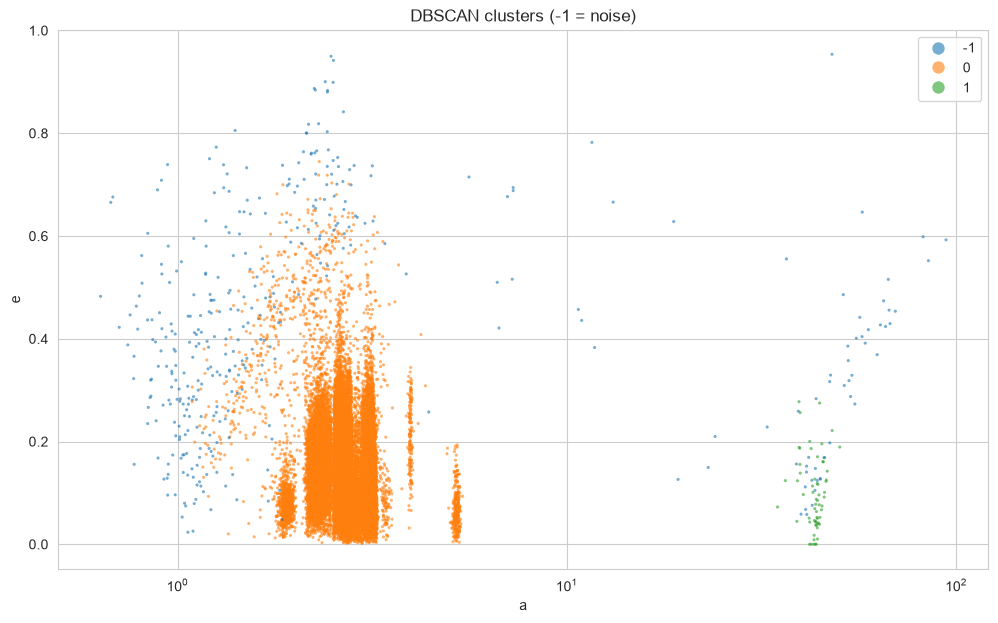

class   AMO  APO  ATE  CEN  IEO  IMB    MBA  MCA  OMB  TJN  TNO
dbscan                                                         
-1       32  209   62   16    2    1      0    5    3    0   49
 0      236  205    0    0    0  628  26818  554  853  265    0
 1        0    0    0    0    0    0      0    0    0    0   62


In [13]:
valid = db_df.dropna(subset=['silhouette'])
best_db = valid.sort_values('silhouette', ascending=False).iloc[0] if len(valid) else db_df.iloc[0]
print("Chosen DBSCAN:", best_db.to_dict())
db_labels = DBSCAN(eps=best_db['eps'], min_samples=int(best_db['min_samples']), n_jobs=-1).fit_predict(X_db)

db_plot = clu.iloc[idx_30k].assign(dbscan=db_labels)
plt.figure(figsize=(12, 7))
sns.scatterplot(data=db_plot, x='a', y='e', hue='dbscan', palette='tab10', s=5, alpha=0.6, linewidth=0)
plt.xscale('log'); plt.title("DBSCAN clusters (-1 = noise)"); plt.legend(markerscale=4); plt.show()

print(pd.crosstab(db_plot['dbscan'], db_plot['class']))

## 7. K-Means vs DBSCAN — comparison table

In [14]:
km_table = pd.DataFrame({'method': 'K-Means', 'params': [f"k={k}" for k in k_range], 'silhouette': sils})
db_table = pd.DataFrame({'method': 'DBSCAN',
                         'params': [f"eps={r.eps}, min_samples={r.min_samples}" for r in db_df.itertuples()],
                         'silhouette': db_df['silhouette'],
                         'n_clusters': db_df['n_clusters'], 'noise_%': db_df['noise_%']})
comparison = pd.concat([km_table, db_table], ignore_index=True)
comparison.round(3)

,method,params,silhouette,n_clusters,noise_%
0,K-Means,k=2,0.871,NaN,NaN
1,K-Means,k=3,0.721,NaN,NaN
2,K-Means,k=4,0.293,NaN,NaN
3,K-Means,k=5,0.308,NaN,NaN
4,K-Means,k=6,0.315,NaN,NaN
5,K-Means,k=7,0.300,NaN,NaN
6,K-Means,k=8,0.295,NaN,NaN
7,K-Means,k=9,0.299,NaN,NaN
8,K-Means,k=10,0.296,NaN,NaN
9,DBSCAN,"eps=0.2229, min_samples=10",0.240,12.0,7.39


**Comparison:**
- **K-Means (k = 5), silhouette 0.308:** assigns every asteroid to a cluster, runs on the full dataset, and can place a new asteroid in a cluster, so it is the model used in the Streamlit app. Its clusters match known orbital families (main belt, near-Earth objects, TNOs).
- **DBSCAN:** finds dense groups of any shape and labels unusual objects as **noise** (mostly rare distant or highly eccentric orbits). eps was tuned with a k-distance graph (see the table above). It needs neighbour searches, so it ran on a 30k sample and cannot assign new points directly.
- **Conclusion:** K-Means is the better choice for this project: it scales to ~930k asteroids, gives interpretable clusters, and supports predictions in the app. DBSCAN is useful for spotting outliers.

## 8. Save K-Means model for the app

In [15]:
artifact = {
    'scaler': scaler, 'kmeans': kmeans, 'features': list(X.columns), 'k': best_k,
    'cluster_names': cluster_names, 'silhouette': km_sil,
    'plot_sample': clu.sample(5000, random_state=RANDOM_STATE)[['a', 'e', 'i', 'cluster']],
}
joblib.dump(artifact, "../models/cluster_model.joblib", compress=3)
print(f"Saved ../models/cluster_model.joblib ({os.path.getsize('../models/cluster_model.joblib')/1e6:.1f} MB)")

Saved ../models/cluster_model.joblib (0.5 MB)
